# TP5 · Ej. 2 — Propuesta A: VAE sobre **HASYv2** (168 236 símbolos matemáticos/científicos manuscritos)
*(Propuesta alternativa; el `ejercicio2.ipynb` original no se modifica.)*

**Dataset (GitHub / Zenodo):** [MartinThoma/HASY](https://github.com/MartinThoma/HASY) — HASYv2: **168 236 imágenes 32×32**, **369 clases** de símbolos LaTeX (α, β, ∑, ∫, ∇, ℏ, ∂, ≤, →, ⊗, †, ⟩ …: matemática, física y notación de computación cuántica).
Es la versión grande y real del dataset de símbolos del ej2 actual (39 símbolos renderizados).

**Pregunta:** ¿un VAE aprende un espacio latente donde los símbolos se organizan por forma, y sus muestras del *prior* "pertenecen" al conjunto? Se mide con distancia de Fréchet (tipo FID) en el espacio de características de un clasificador *juez*, como en el ej2 original, comparando contra el AE puro (β=0).

> Colab: *Entorno de ejecución → Cambiar tipo → GPU (T4)* y *Ejecutar todo*. ~10 min en GPU.

In [1]:
# ---- Configuración ---------------------------------------------------------------------------
RAPIDO = False        # True = prueba de humo (subconjunto, pocas épocas)
SEED   = 0
D_LAT  = 32           # dimensión latente
EPOCAS = 25
BETAS  = [0.0, 1.0, 4.0]   # 0 = autoencoder; 1 = VAE; 4 = beta-VAE
import os, tarfile, urllib.request, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy import linalg
torch.manual_seed(SEED); np.random.seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print('dispositivo:', dev)

dispositivo: cuda


In [2]:
# ---- Descarga (34 MB) y carga de HASYv2 -----------------------------------------------------------
URL = 'https://zenodo.org/records/259444/files/HASYv2.tar.bz2'
if not os.path.exists('HASYv2'):
    print('descargando…'); urllib.request.urlretrieve(URL, 'HASYv2.tar.bz2')
    with tarfile.open('HASYv2.tar.bz2') as t: t.extractall('HASYv2')
lab = pd.read_csv('HASYv2/hasy-data-labels.csv')
print(lab.shape); print(lab.head(3)); print('clases:', lab.symbol_id.nunique())
if RAPIDO: lab = lab.sample(8000, random_state=0)
def cargar(p): return 1.0 - np.asarray(Image.open('HASYv2/' + p).convert('L'), dtype=np.float32) / 255.0   # tinta = 1
X = np.stack([cargar(p) for p in lab.path.values])[:, None]        # (N,1,32,32)
latex = lab.latex.values
cls, y = np.unique(lab.symbol_id.values, return_inverse=True); NC = len(cls)
print('imágenes:', X.shape, '| clases:', NC, '| media de tinta:', X.mean().round(3))

descargando…


/tmp/ipykernel_387/160186073.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open('HASYv2.tar.bz2') as t: t.extractall('HASYv2')


(168233, 4)
                     path  symbol_id latex  user_id
0  hasy-data/v2-00000.png         31     A       50
1  hasy-data/v2-00001.png         31     A       10
2  hasy-data/v2-00002.png         31     A       43
clases: 369
imágenes: (168233, 1, 32, 32) | clases: 369 | media de tinta: 0.167


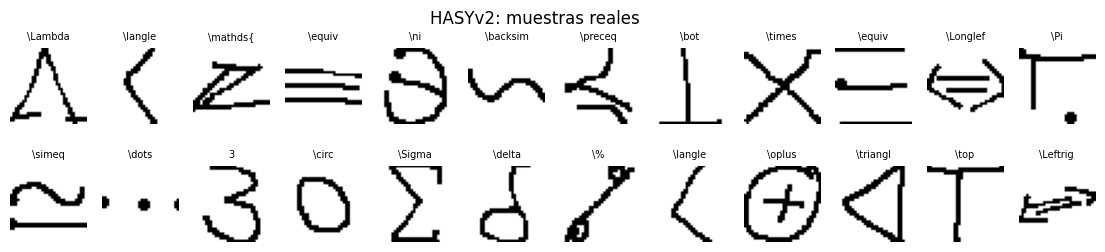

más frecuentes:
 \int      3514
\sum      3400
\infty    2914
Name: count, dtype: int64 
menos frecuentes:
 \mathbb{Q}    53
j             53
\mathbb{N}    51
Name: count, dtype: int64


In [3]:
# ---- Partición y vista rápida ----------------------------------------------------------------------
rng = np.random.default_rng(SEED); idx = rng.permutation(len(X)); ntr = int(.9 * len(X))
tr, te = idx[:ntr], idx[ntr:]
Xtr, Xte, ytr, yte = [torch.tensor(a) for a in (X[tr], X[te], y[tr], y[te])]
fig, ax = plt.subplots(2, 12, figsize=(14, 2.8))
for a, i in zip(ax.ravel(), rng.choice(len(X), 24, replace=False)):
    a.imshow(X[i, 0], cmap='gray_r'); a.set_title(latex[i][:8], fontsize=7); a.axis('off')
plt.suptitle('HASYv2: muestras reales'); plt.show()
cnt = pd.Series(latex).value_counts(); print('más frecuentes:\n', cnt.head(3), '\nmenos frecuentes:\n', cnt.tail(3))

## 1. Modelos
* **Juez**: CNN que clasifica las clases; su capa penúltima (128-d) da el espacio de características para la distancia de Fréchet.
* **VAE convolucional**: codificador conv → (μ, log σ²) ∈ ℝ^d; decodificador conv-transpuesta → 32×32; pérdida = BCE + β·KL. Con β=0 es un autoencoder común.

In [4]:
class Juez(nn.Module):
    def __init__(s, nc):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                            nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(2),nn.Flatten(),
                            nn.Linear(512,128),nn.ReLU())
        s.o = nn.Linear(128, nc)
    def forward(s, x): return s.o(s.f(x))
    def feats(s, x): return s.f(x)

class VAE(nn.Module):
    def __init__(s, d=D_LAT):
        super().__init__()
        s.enc = nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.ReLU(),nn.Conv2d(32,64,4,2,1),nn.ReLU(),
                              nn.Conv2d(64,128,4,2,1),nn.ReLU(),nn.Flatten())          # 128*4*4
        s.mu, s.lv = nn.Linear(2048,d), nn.Linear(2048,d)
        s.fc = nn.Linear(d,2048)
        s.dec = nn.Sequential(nn.ConvTranspose2d(128,64,4,2,1),nn.ReLU(),nn.ConvTranspose2d(64,32,4,2,1),nn.ReLU(),
                              nn.ConvTranspose2d(32,1,4,2,1))
    def encode(s, x): h = s.enc(x); return s.mu(h), s.lv(h)
    def decode(s, z): return s.dec(F.relu(s.fc(z)).view(-1,128,4,4))                    # logits
    def forward(s, x):
        mu, lv = s.encode(x); z = mu + torch.randn_like(mu)*torch.exp(.5*lv)
        return s.decode(z), mu, lv

def entrenar(modelo, loss_fn, Xt, ep, bs=256, lr=2e-3, yt=None):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr); n = len(Xt)
    for e in range(ep):
        perm = torch.randperm(n); tot = 0
        for i in range(0, n, bs):
            b = perm[i:i+bs]; xb = Xt[b].to(dev)
            l = loss_fn(modelo, xb, yt[b].to(dev) if yt is not None else None)
            opt.zero_grad(); l.backward(); opt.step(); tot += l.item()*len(b)
        if e % max(1, ep//5) == 0 or e == ep-1: print(f'  época {e+1}/{ep}  pérdida {tot/n:.4f}')
    return modelo

EP = 3 if RAPIDO else EPOCAS
print('Entrenando juez…')
juez = Juez(NC).to(dev)
entrenar(juez, lambda m,x,y: F.cross_entropy(m(x), y), Xtr, 3 if RAPIDO else 8, yt=ytr)
juez.eval()
with torch.no_grad(): acc = (juez(Xte.to(dev)).argmax(1).cpu()==yte).float().mean().item()
print(f'Exactitud del juez en test: {acc:.3f}')

Entrenando juez…
  época 1/8  pérdida 2.0539
  época 2/8  pérdida 0.8992
  época 3/8  pérdida 0.7564
  época 4/8  pérdida 0.6825
  época 5/8  pérdida 0.6379
  época 6/8  pérdida 0.6040
  época 7/8  pérdida 0.5773
  época 8/8  pérdida 0.5560
Exactitud del juez en test: 0.812


In [5]:
def vae_loss(beta):
    def f(m, x, _):
        lg, mu, lv = m(x)
        rec = F.binary_cross_entropy_with_logits(lg, x, reduction='sum')/len(x)
        kl = (-0.5*(1+lv-mu**2-lv.exp()).sum(1)).mean()
        return rec + beta*kl
    return f
modelos = {}
for b in BETAS:
    print(f'Entrenando VAE β={b}…'); torch.manual_seed(SEED)
    modelos[b] = entrenar(VAE().to(dev), vae_loss(b), Xtr, EP).eval()

Entrenando VAE β=0.0…
  época 1/25  pérdida 209.5244
  época 6/25  pérdida 86.3112
  época 11/25  pérdida 79.8488
  época 16/25  pérdida 76.6083
  época 21/25  pérdida 74.8645
  época 25/25  pérdida 73.6525
Entrenando VAE β=1.0…
  época 1/25  pérdida 284.9419
  época 6/25  pérdida 173.2484
  época 11/25  pérdida 167.6010
  época 16/25  pérdida 164.6763
  época 21/25  pérdida 162.7736
  época 25/25  pérdida 161.6320
Entrenando VAE β=4.0…
  época 1/25  pérdida 374.6489
  época 6/25  pérdida 290.1746
  época 11/25  pérdida 284.8063
  época 16/25  pérdida 282.0785
  época 21/25  pérdida 280.1466
  época 25/25  pérdida 279.0587


## 2. ¿Las muestras "pertenecen" al conjunto? — distancia de Fréchet en el espacio del juez
FD = ‖μ₁−μ₂‖² + Tr(Σ₁+Σ₂−2(Σ₁Σ₂)^½). Referencia (piso): FD entre dos mitades de imágenes reales de test.

/tmp/ipykernel_387/3078522252.py:6: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cs = linalg.sqrtm(s1@s2); cs = cs.real if np.iscomplexobj(cs) else cs


piso real↔real: 1.43
β=0.0: FD(prior→real) = 437.61
β=1.0: FD(prior→real) = 202.02
β=4.0: FD(prior→real) = 276.07


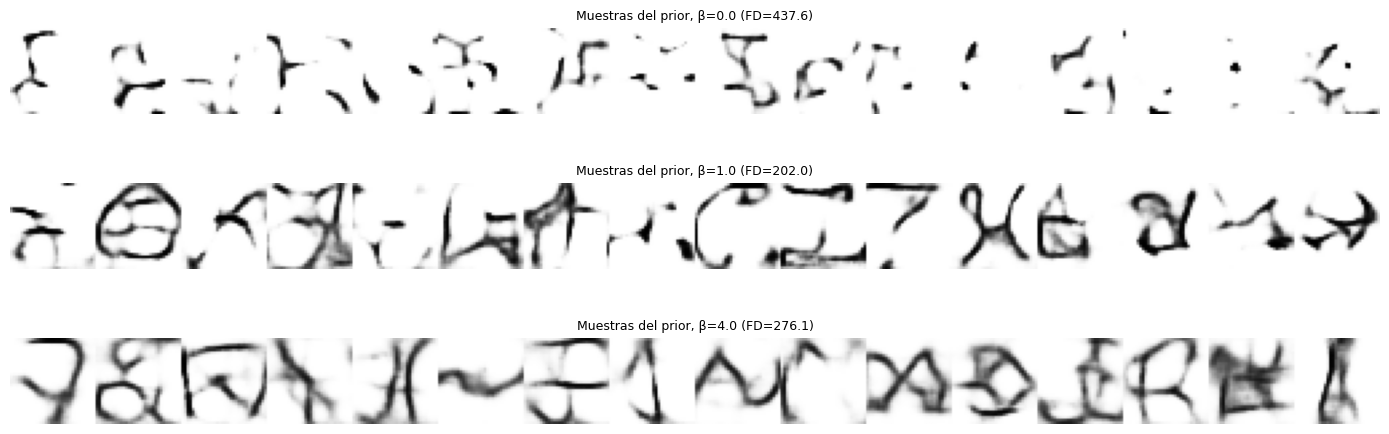

In [6]:
@torch.no_grad()
def feats(imgs, bs=2048):
    return torch.cat([juez.feats(imgs[i:i+bs].to(dev)).cpu() for i in range(0,len(imgs),bs)]).numpy().astype(np.float64)
def frechet(a, b):
    m1, m2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a,rowvar=False), np.cov(b,rowvar=False)
    cs = linalg.sqrtm(s1@s2); cs = cs.real if np.iscomplexobj(cs) else cs
    return float(((m1-m2)**2).sum() + np.trace(s1+s2-2*cs))
@torch.no_grad()
def muestrear(m, n=4000):
    z = torch.randn(n, D_LAT, device=dev); return torch.sigmoid(m.decode(z)).cpu()
Fte = feats(Xte); h = len(Fte)//2
piso = frechet(Fte[:h], Fte[h:]); print(f'piso real↔real: {piso:.2f}')
res = {}
for b, m in modelos.items():
    S = muestrear(m); res[b] = frechet(feats(S), Fte); print(f'β={b}: FD(prior→real) = {res[b]:.2f}')
fig, ax = plt.subplots(len(BETAS), 1, figsize=(14, 1.7*len(BETAS)))
for a, b in zip(np.atleast_1d(ax), BETAS):
    S = muestrear(modelos[b], 16); a.imshow(torch.cat(list(S[:,0]),1), cmap='gray_r'); a.set_title(f'Muestras del prior, β={b} (FD={res[b]:.1f})', fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Espacio latente: ¿se organizan los símbolos por forma?
Proyección PCA del μ del VAE (β=1) y interpolación entre dos símbolos reales.

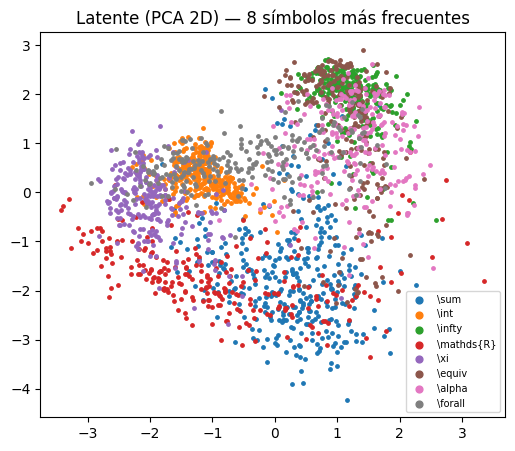

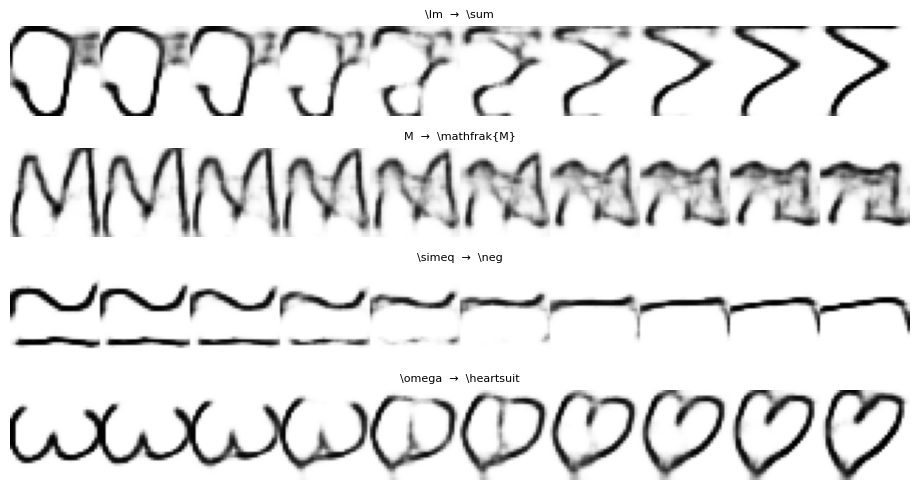

In [7]:
from sklearn.decomposition import PCA
mB = modelos[1.0] if 1.0 in modelos else modelos[BETAS[0]]
with torch.no_grad(): MU = torch.cat([mB.encode(Xte[i:i+2048].to(dev))[0].cpu() for i in range(0,len(Xte),2048)]).numpy()
P = PCA(2).fit_transform(MU); yl = latex[te]
top = pd.Series(yl).value_counts().index[:8]
plt.figure(figsize=(6,5))
for t in top:
    k = yl==t; plt.scatter(P[k,0],P[k,1],s=6,label=t)
plt.legend(fontsize=7,markerscale=2); plt.title('Latente (PCA 2D) — 8 símbolos más frecuentes'); plt.show()
def interp(i, j, n=10):
    with torch.no_grad():
        a, b = mB.encode(Xte[[i,j]].to(dev))[0]
        z = torch.stack([a*(1-t)+b*t for t in np.linspace(0,1,n)]); return torch.sigmoid(mB.decode(z)).cpu()
fig, ax = plt.subplots(4, 1, figsize=(12, 5))
for a, (i,j) in zip(ax, rng.choice(len(Xte), (4,2))):
    a.imshow(torch.cat(list(interp(i,j)[:,0]),1), cmap='gray_r'); a.set_title(f'{latex[te][i]}  →  {latex[te][j]}', fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

## 4. Guía de conclusiones
* ¿Qué β da la menor FD? ¿El AE (β=0) reconstruye bien pero genera basura desde el prior (huecos en el latente)?
* ¿Qué clases se mezclan en las interpolaciones (p. ej. `0`/`O`, `\\alpha`/`\\propto`)?
* Extensiones: VAE **condicional** (one-hot de clase) para "dame un ∑ nuevo"; restringir a símbolos de física cuántica (`\\otimes`, `\\dagger`, `\\rangle`, `\\hbar`, `\\psi`).
* Citas: Thoma (2017), *The HASYv2 dataset*, arXiv:1701.08380; Kingma & Welling (2014); Higgins et al. (2017); Heusel et al. (2017).